# 03 · How the elasticity varies

Results from `python -m econocausal.run_dml` on the real data:

* **by category**: own DML, separate final stage per category on shared residuals
* **by product**: causal forest fitted on the same DML residuals, with product-level effect
  modifiers (category, typical price, typical guest and UK share)

Average elasticity (own DML): **−1.28**.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

from econocausal.data.db import get_engine, load_panel, read_table
from econocausal.viz import BLUE, GREY, TEXT_MUTED, save_figure, set_style

set_style()
pd.set_option("display.float_format", "{:,.3f}".format)

engine = get_engine()
overall = read_table("results", engine).query("dataset == 'real' and method == 'dml_manual'")["estimate"].iloc[0]
categories = read_table("segment_elasticity", engine).query(
    "dataset == 'real' and method == 'dml_manual' and segment == 'category'"
).sort_values("estimate")
products = read_table("product_elasticity", engine).query("dataset == 'real' and method == 'causal_forest'")

panel = load_panel()
by_product = panel.groupby("stock_code").agg(guest_share=("guest_share", "mean"), price=("price", "median"))
products = products.merge(by_product, left_on="stock_code", right_index=True)
print(f"overall {overall:.3f} · {len(categories)} categories · {len(products):,} products")

overall -1.275 · 11 categories · 1,877 products


## 1. By category

,value,estimate,ci_low,ci_high,n_groups,n_obs
0,garden,-1.570,-1.780,-1.360,38,2493
1,candles_lighting,-1.526,-1.662,-1.390,157,10085
2,bags,-1.368,-1.552,-1.184,94,7330
3,other,-1.288,-1.355,-1.221,699,47047
4,stationery_cards,-1.281,-1.441,-1.121,168,12069
5,home_decor,-1.260,-1.371,-1.148,249,16578
6,kitchen_dining,-1.217,-1.345,-1.088,258,19211
7,toys_kids,-1.179,-1.476,-0.882,59,4289
8,christmas,-1.109,-1.305,-0.913,60,2812
9,jewellery,-0.960,-1.201,-0.719,71,3418


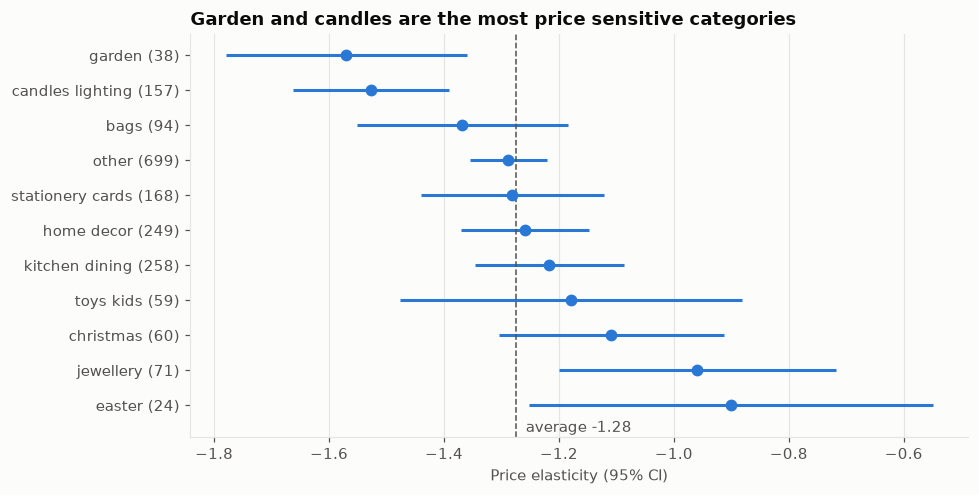

In [2]:
fig, ax = plt.subplots(figsize=(9, 4.6))
y = np.arange(len(categories))
labels = [f"{v.replace('_', ' ')} ({n})" for v, n in zip(categories["value"], categories["n_groups"])]
ax.errorbar(categories["estimate"], y,
            xerr=[categories["estimate"] - categories["ci_low"], categories["ci_high"] - categories["estimate"]],
            fmt="none", ecolor=BLUE, elinewidth=2)
ax.scatter(categories["estimate"], y, color=BLUE, s=45, zorder=3)
ax.axvline(overall, color=TEXT_MUTED, linestyle="--", linewidth=1)
ax.text(overall, len(categories) - 0.35, f"  average {overall:.2f}", color=TEXT_MUTED, va="center")
ax.set_ylim(len(categories) - 0.1, -0.6)
ax.set_yticks(y, labels)
ax.set_xlabel("Price elasticity (95% CI)")
ax.set_title("Garden and candles are the most price sensitive categories")
ax.grid(axis="y", visible=False)
fig.tight_layout()
save_figure(fig, "09_category_elasticities")
categories[["value", "estimate", "ci_low", "ci_high", "n_groups", "n_obs"]]

Every category is price sensitive (all intervals below zero). Number of products in brackets:
categories with few products (Easter, garden) have wide intervals.

## 2. By product (causal forest)

,value
products,"1,877.000"
median elasticity,-1.314
10th percentile,-1.642
90th percentile,-0.977
share with 95% CI below zero,0.999
median CI width,0.557


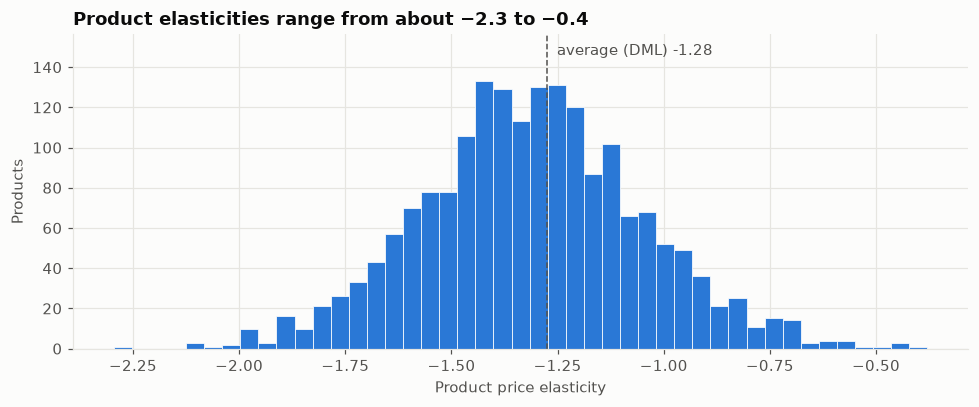

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(products["estimate"], bins=45, color=BLUE, edgecolor="white", linewidth=0.5)
ax.axvline(overall, color=TEXT_MUTED, linestyle="--", linewidth=1)
top = ax.get_ylim()[1]
ax.set_ylim(0, top * 1.12)
ax.text(overall, top * 1.06, f"  average (DML) {overall:.2f}", color=TEXT_MUTED, va="center")
ax.set_xlabel("Product price elasticity")
ax.set_ylabel("Products")
ax.set_title("Product elasticities range from about −2.3 to −0.4")
fig.tight_layout()
save_figure(fig, "10_product_elasticity_distribution")

pd.Series({
    "products": len(products),
    "median elasticity": products["estimate"].median(),
    "10th percentile": products["estimate"].quantile(0.1),
    "90th percentile": products["estimate"].quantile(0.9),
    "share with 95% CI below zero": (products["ci_high"] < 0).mean(),
    "median CI width": (products["ci_high"] - products["ci_low"]).median(),
}).to_frame("value")

Individual product estimates are uncertain (median interval width about 0.56), so the forest is
most useful for the **pattern** of who is more or less price sensitive, not for exact values per product.

What drives the differences? The forest's feature importances:

In [4]:
importance = pd.read_csv("../reports/forest_feature_importance.csv", index_col=0)["importance"]
importance.head(6).to_frame()

,importance
guest_share_mean,0.611
log_price_level,0.259
uk_share_mean,0.081
category_candles_lighting,0.025
category_kitchen_dining,0.006
category_toys_kids,0.005


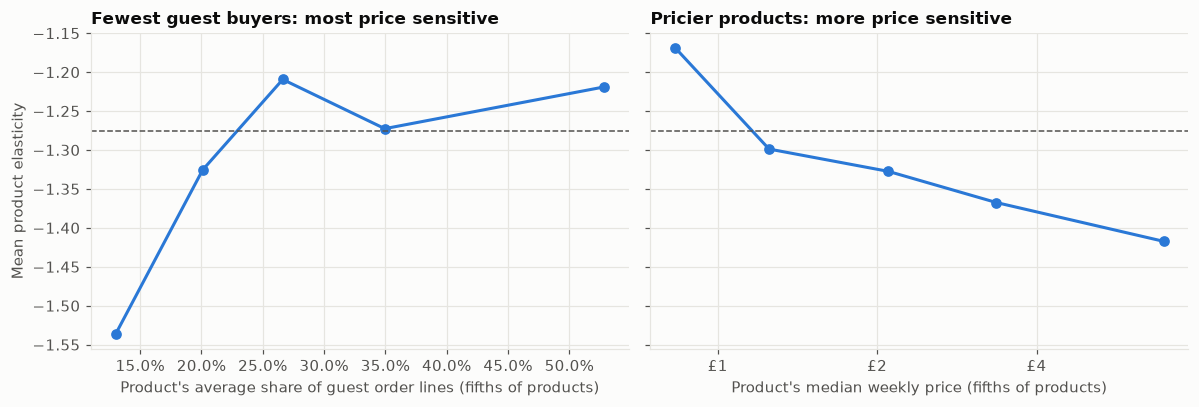

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, col, label, fmt in [
    (axes[0], "guest_share", "Product's average share of guest order lines", mticker.PercentFormatter(1.0)),
    (axes[1], "price", "Product's median weekly price", mticker.StrMethodFormatter("£{x:.2f}")),
]:
    bins = pd.qcut(products[col], 5)
    grouped = products.groupby(bins, observed=True).agg(x=(col, "median"), estimate=("estimate", "mean"))
    ax.plot(grouped["x"], grouped["estimate"], color=BLUE, marker="o", markersize=6)
    ax.axhline(overall, color=TEXT_MUTED, linestyle="--", linewidth=1)
    ax.set_xlabel(label + " (fifths of products)")
    ax.xaxis.set_major_formatter(fmt)
axes[1].set_xscale("log")
axes[1].xaxis.set_major_locator(mticker.FixedLocator([0.5, 1, 2, 4, 8]))
axes[1].xaxis.set_minor_locator(mticker.NullLocator())
axes[1].xaxis.set_major_formatter(mticker.StrMethodFormatter("£{x:g}"))
axes[0].set_ylabel("Mean product elasticity")
axes[0].set_title("Fewest guest buyers: most price sensitive", fontsize=11)
axes[1].set_title("Pricier products: more price sensitive", fontsize=11)
fig.tight_layout()
save_figure(fig, "11_elasticity_drivers")

* Products bought almost only by **registered (largely wholesale) customers** are the most price
  sensitive: about −1.54 for the fifth with the fewest guest buyers, against −1.21 to −1.33 for the
  other fifths (above a guest share of about 25% there is no clear further trend). Trade buyers compare
  prices and buy in bulk, so price matters more to them.
* **More expensive products** are more price sensitive (about −1.17 for the cheapest fifth vs −1.42 for
  the most expensive). A 1% change is more money on a £10 item than on a £0.50 one.
* Once these are known, the **category adds little** (low importance), which is why the category
  estimates in section 1 are fairly close together.